# Проверка решений команд

Положите присланные папки или ZIP-архивы (из `export_solution`) в папку `SUBMISSIONS`, по одной на команду,
и выполните все ячейки. Оценка — на закрытой зоне по тем же правилам, что в ноутбуке команд.
Загрузка решения выполняет код команды: кладите сюда только решения участников.

In [1]:
from pathlib import Path
import sys

from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from cycle_routing.grading import grade_all, load_submissions, submissions_table
from cycle_routing.workshop import load_city
from cycle_routing.workshop_maps import route_explorer

PACK = "konstanz_more"  # тот же набор, что у команд
SUBMISSIONS = ROOT / "outputs/hackathon/submissions"  # сюда — папки или ZIP команд
city = load_city(ROOT / "notebooks/data/hackathon" / PACK)
PRIVATE = ROOT / "outputs/hackathon_private" / PACK
OUTPUT = ROOT / "outputs/hackathon/grading" / PACK
OUTPUT.mkdir(parents=True, exist_ok=True)

## 1. Решения

In [2]:
teams = load_submissions(SUBMISSIONS, city)
submissions_table(teams)

,решение,статус
команда,,
Архивом,цена по типу дороги,ок
Без поворотов,веса + минимум поворотов,ок
Без тротуаров,веса без тротуаров,ок
Велосипедисты,веса + ML,ок
Пустая папка,,не загружено: нет submission.json: пришлите па...
Старый набор,,не загружено: решение сделано для другого набо...
Табличка,цена по типу дороги,ок


## 2. Итог на закрытой зоне

**ярус** — команды одного яруса не различаются: разница в пределах шума закрытых пар.
**популярность, закрытая зона** — итоговая оценка, **±** — её 90% интервал.
**популярность, открытая зона** — для сравнения: так решение выглядело у команды.

Команды:   0%|          | 0/7 [00:00<?, ?it/s]

Команды: 100%|██████████| 7/7 [00:07<00:00,  1.10s/it]


,ярус,"популярность, закрытая зона",±,"популярность, открытая зона",популярнее кратчайшего,"объезд, %",поворотов,"неудобные участки, м","время поиска, мс"
Велосипедисты,1,71.3,3.3,70.9,27 из 36,8.3,10.0,0.0,15.17
Без поворотов,2,65.6,4.5,64.3,23 из 36,6.4,4.0,0.0,30.62
Архивом,3,63.2,4.4,64.6,13 из 36,0.4,11.5,0.0,9.95
Табличка,3,63.2,4.4,64.6,13 из 36,0.4,11.5,0.0,13.87
Без тротуаров,3,61.1,6.0,54.0,19 из 36,2.3,7.9,0.0,24.81
кратчайший,4,61.1,4.0,60.7,—,0.0,9.8,0.0,14.17


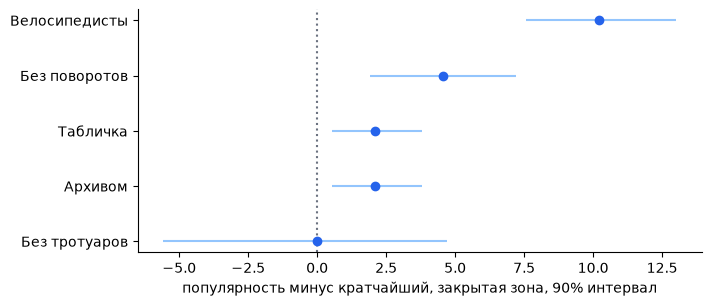

In [3]:
board = grade_all(city, PRIVATE, teams)
board.table.to_csv(OUTPUT / "leaderboard.csv")
display(board.table)
board.plot();

In [4]:
board.errors if len(board.errors) else "Все решения оценены."

,статус
команда,
Пустая папка,не загружено: нет submission.json: пришлите па...
Старый набор,не загружено: решение сделано для другого набо...


## 3. Маршруты на закрытой зоне

In [5]:
route_explorer(board.result.lab, board.result, filename=OUTPUT / "closed_routes.html")

## 4. Баллы по парам

In [6]:
by_pair = board.result.per_od.pivot(index="od_id", columns="algorithm", values="counted").rename(columns={"shortest": "кратчайший"})
by_pair.to_csv(OUTPUT / "by_pair.csv")
by_pair.round(0)

algorithm,кратчайший,Архивом,Без поворотов,Без тротуаров,Велосипедисты,Табличка
od_id,,,,,,
CL01,62.0,62.0,38.0,62.0,62.0,62.0
CL02,89.0,89.0,88.0,85.0,82.0,89.0
CL03,62.0,80.0,90.0,80.0,84.0,80.0
CL04,72.0,83.0,69.0,85.0,78.0,83.0
CL05,55.0,59.0,64.0,76.0,76.0,59.0
CL06,72.0,73.0,78.0,72.0,70.0,73.0
CL07,42.0,36.0,42.0,45.0,48.0,36.0
CL08,71.0,69.0,63.0,70.0,68.0,69.0
CL09,57.0,65.0,74.0,0.0,72.0,65.0
